# CSE558 - Data Science Assignment : JL with Linear Regression


# Importing all Required Libraries

In [ ]:
from sklearn.datasets import fetch_kddcup99
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
import time

encoder = OneHotEncoder(sparse_output=False)

# Loading Dataset

In [ ]:
kdd = fetch_kddcup99(subset=None, as_frame=True)

# Preparing the data

In [ ]:
D = kdd.data

print("Before: ")
print("protocol_type",D["protocol_type"].shape)
print("service",D["service"].shape)
print("flag",D["flag"].shape)
print()
print("Matrix Size: ", D.shape)

convert_to_float = FunctionTransformer(lambda x: x.astype(float))
columns_ohe = ["protocol_type","service","flag"]
ct = ColumnTransformer(transformers=[('encoder',encoder,columns_ohe)],remainder=convert_to_float)

new_D = ct.fit_transform(D)
print("Matrix Size After encoding, and float conversion: ",new_D.shape)

# Dropping const colums
const_cols = []
for i in range(new_D.shape[1]):
  col = new_D[:,i]
  if len(np.unique(col))==1:
    const_cols.append(i)

new_D = np.delete(new_D,const_cols,axis=1)
print("Matrix Size After Dropping: ",new_D.shape)

col_min = new_D.min(axis=0)
col_max = new_D.max(axis=0)
col_range = col_max - col_min
col_range[col_range == 0] = 1
new_D = (new_D - col_min) / col_range

print("Matrix Size After Rescaling: ",new_D.shape)

# for the record.
print("Number of Rows: ",new_D.shape[0])
print("NUmber of Columns: ",new_D.shape[1])

Before: 
protocol_type (494021,)
service (494021,)
flag (494021,)

Matrix Size:  (494021, 41)
Matrix Size After encoding, and float conversion:  (494021, 118)
Matrix Size After Dropping:  (494021, 116)
Matrix Size After Rescaling:  (494021, 116)
Number of Rows:  494021
NUmber of Columns:  116


In [ ]:
D = new_D
y = (kdd.target != b'normal.').to_numpy(dtype=float)

Setup

In [ ]:
n, d = D.shape
print("n =", n, " d =", d, " fraction of attacks =", y.mean())

n = 494021  d = 116  fraction of attacks = 0.8030893423558918


Functions

In [ ]:
def loss(X, t, a):
    r = X @ a - t
    return float(r @ r)

def solve(X, t):
    return np.linalg.lstsq(X, t, rcond=None)[0]

def count_sketch(X, t, m, rng):
    n_rows = X.shape[0]
    h = rng.integers(0, m, size=n_rows)                 # bucket h(i), uniform on {0..m-1}
    sigma = rng.choice([-1.0, 1.0], size=n_rows)        # sign sigma(i)
    SX = np.zeros((m, X.shape[1]))
    np.add.at(SX, h, sigma[:, None] * X)
    St = np.zeros(m)
    np.add.at(St, h, sigma * t)
    return SX, St

Q2(a)

In [ ]:
t0 = time.perf_counter()
b = solve(D, y)
time_b = time.perf_counter() - t0
loss_b = loss(D, y, b)
rank_D = int(np.linalg.matrix_rank(D))
print(f"Loss(D, y, b) = {loss_b:.6f}")
print(f"time to compute b = {time_b:.2f} s")
print(f"rank(D) = {rank_D}   (d = {d})")

Loss(D, y, b) = 2949.788844
time to compute b = 10.48 s
rank(D) = 113   (d = 116)


Q2(b)

m = 50 done
m = 100 done
m = 200 done
m = 500 done
m = 1000 done
m = 2000 done
m = 5000 done
   m  run  Loss(D,y,a~)     ratio  sketched loss
  50    1  14008.735678  4.749064   5.116504e-24
  50    2  10019.981391  3.396847   5.074781e-24
  50    3   7678.942980  2.603218   6.441649e-25
  50    4   8847.659107  2.999421   3.978756e-24
  50    5   9496.049133  3.219230   5.467374e-24
 100    1  26980.776544  9.146681   1.416632e-23
 100    2  32602.993418 11.052653   2.360912e-23
 100    3  55065.546560 18.667623   4.813796e-23
 100    4  40439.074346 13.709142   3.393937e-23
 100    5  33599.504253 11.390478   4.195290e-23
 200    1   8968.485374  3.040382   1.149414e+03
 200    2   6865.195467  2.327351   1.466463e+03
 200    3   7189.707317  2.437363   1.370582e+03
 200    4   6894.635775  2.337332   1.177253e+03
 200    5   8106.003062  2.747994   1.092979e+03
 500    1   3918.859392  1.328522   2.159576e+03
 500    2   3973.896858  1.347180   2.358397e+03
 500    3   3676.342158  

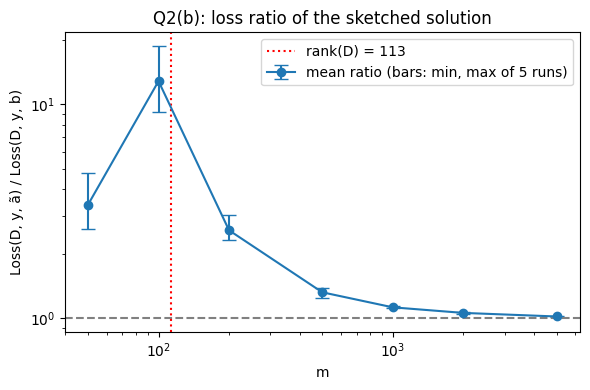

In [ ]:
M_LIST = [50, 100, 200, 500, 1000, 2000, 5000]
loss_runs = []
ratio_runs = []
sk_runs = []
t = []
for i in range(len(M_LIST)):
    m = M_LIST[i]
    rng = np.random.default_rng(m)
    loss_i = []
    ratio_i = []
    sk_i = []
    t_i = []
    for j in range(5):
        t0 = time.perf_counter()
        SD, Sy = count_sketch(D, y, m, rng)
        a = solve(SD, Sy)
        t_i.append(time.perf_counter() - t0)
        L = loss(D, y, a)
        loss_i.append(L)
        ratio_i.append(L / loss_b)
        sk_i.append(loss(SD, Sy, a))
    loss_runs.append(loss_i)
    ratio_runs.append(ratio_i)
    sk_runs.append(sk_i)
    t.append(t_i)
    print("m =", m, "done")

losses = np.array(loss_runs)
ratios = np.array(ratio_runs)
sk = np.array(sk_runs)
times = np.array(t)

# every run
table_runs = pd.DataFrame({
    "m": np.repeat(M_LIST, 5),
    "run": np.tile(np.arange(1, 6), len(M_LIST)),
    "Loss(D,y,a~)": losses.flatten(),
    "ratio": ratios.flatten(),
    "sketched loss": sk.flatten(),
})
print(table_runs.to_string(index=False))

# mean, smallest and largest ratio for each m
mean_r = ratios.mean(axis=1)
min_r = ratios.min(axis=1)
max_r = ratios.max(axis=1)
table = pd.DataFrame({"m": M_LIST, "mean": mean_r, "min": min_r, "max": max_r,
                      "mean sketched loss": sk.mean(axis=1)})
print(table.to_string(index=False))

yerr = np.array([mean_r - min_r, max_r - mean_r])
plt.figure(figsize=(6, 4))
plt.errorbar(M_LIST, mean_r, yerr=yerr, fmt="o-", capsize=5, label="mean ratio (bars: min, max of 5 runs)")
plt.axhline(1, linestyle="--", color="gray")
plt.axvline(rank_D, linestyle=":", color="red", label=f"rank(D) = {rank_D}")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("m")
plt.ylabel("Loss(D, y, ã) / Loss(D, y, b)")
plt.title("Q2(b): loss ratio of the sketched solution")
plt.legend()
plt.tight_layout()
plt.show()

Q2(c)

In [ ]:
mean_t = times.mean(axis=1)
table_t = pd.DataFrame({"m": M_LIST, "mean time (s)": mean_t, "speed-up vs exact": time_b / mean_t})
print(table_t.to_string(index=False))
print("exact solve on D (a):", time_b, "s")

   m  mean time (s)  speed-up vs exact
  50       2.185788           4.796154
 100       2.370174           4.423041
 200       2.195234           4.775517
 500       2.077310           5.046610
1000       2.254010           4.650990
2000       2.296773           4.564394
5000       2.446674           4.284746
exact solve on D (a): 10.483376757000087 s


Q2(d)

   m     mean      std
  50 0.989095 0.187592
 500 0.996486 0.067633
5000 1.000000 0.021356


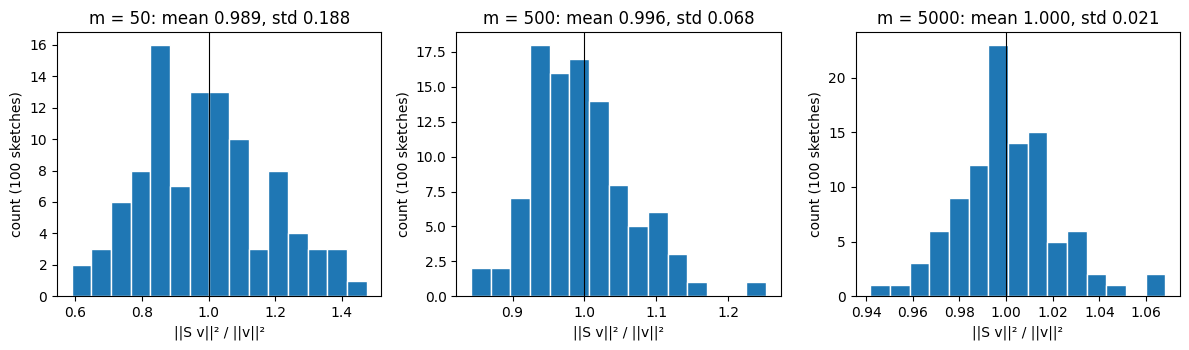

In [ ]:
v = D @ b - y
v2 = float(v @ v)
M_D = [50, 500, 5000]
N_D = 100
ratios_d = {}
for m in M_D:
    rng = np.random.default_rng(10000 + m)
    r = np.empty(N_D)
    for j in range(N_D):
        h = rng.integers(0, m, size=n)
        sigma = rng.choice([-1.0, 1.0], size=n)
        Sv = np.zeros(m)
        np.add.at(Sv, h, sigma * v)
        r[j] = float(Sv @ Sv) / v2
    ratios_d[m] = r

stats_d = pd.DataFrame({
    "m": M_D,
    "mean": [ratios_d[m].mean() for m in M_D],
    "std": [ratios_d[m].std(ddof=1) for m in M_D],
})
print(stats_d.to_string(index=False))
plt.figure(figsize=(12, 3.6))
for i in range(len(M_D)):
    m = M_D[i]
    plt.subplot(1, 3, i + 1)
    plt.hist(ratios_d[m], bins=15, edgecolor="white")
    plt.axvline(1, color="k", linewidth=0.8)
    plt.xlabel("||S v||² / ||v||²")
    plt.ylabel("count (100 sketches)")
    plt.title(f"m = {m}: mean {ratios_d[m].mean():.3f}, std {ratios_d[m].std(ddof=1):.3f}")
plt.tight_layout()
plt.show()

Q2(e)

In [ ]:
N_SUB = 50_000
M_E = 500
rng_e = np.random.default_rng(67)
idx = rng_e.choice(n, size=N_SUB, replace=False)
Dp, yp = D[idx], y[idx]
bp = solve(Dp, yp)
loss_bp = loss(Dp, yp, bp)
print("Loss(D', y', b') =", loss_bp)
t_cs = []
r_cs = []
t_dg = []
r_dg = []
for j in range(5):
    # (i) CountSketch
    t0 = time.perf_counter()
    SD, Sy = count_sketch(Dp, yp, M_E, rng_e)
    t_cs.append(time.perf_counter() - t0)
    a = solve(SD, Sy)
    r_cs.append(loss(Dp, yp, a) / loss_bp)
    # (ii) dense Gaussian S
    t0 = time.perf_counter()
    S = rng_e.normal(0.0, 1.0 / np.sqrt(M_E), size=(M_E, N_SUB))
    SD = S @ Dp
    Sy = S @ yp
    t_dg.append(time.perf_counter() - t0)
    a = solve(SD, Sy)
    r_dg.append(loss(Dp, yp, a) / loss_bp)

print("CountSketch times:", t_cs)
print("CountSketch ratios:", r_cs)
print("Dense Gaussian times:", t_dg)
print("Dense Gaussian ratios:", r_dg)

table_e = pd.DataFrame({
    "method": ["CountSketch", "Dense Gaussian"],
    "mean time (s)": [np.mean(t_cs), np.mean(t_dg)],
    "mean ratio": [np.mean(r_cs), np.mean(r_dg)],
})
print(table_e.to_string(index=False))

Loss(D', y', b') = 261.1445888449915
CountSketch times: [0.30657891200007725, 0.2793501770001967, 0.2629663369998525, 0.17538168299984136, 0.18232012600014968]
CountSketch ratios: [1.2959147143839471, 1.2150224077602456, 1.2626039367673243, 1.3415542780758936, 1.2842581347768884]
Dense Gaussian times: [1.1664631249998365, 1.1019566539998777, 0.7331051070000285, 0.7505538179998439, 0.7185051189999285]
Dense Gaussian ratios: [1.2518717362102538, 1.328655288210147, 1.2739651598952608, 1.2977770972258797, 1.27065731290066]
        method  mean time (s)  mean ratio
   CountSketch       0.241319    1.279871
Dense Gaussian       0.894117    1.284585
